In [1]:
from os import chdir
from os.path import abspath
thepath = abspath("../base")
chdir(thepath)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from stl import Mesh
import iterative_section_minimiser as ism
from geometry import rotate

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [3]:
# read the mesh file and its adjacent triangles. 
mesh_data = Mesh.from_file("../data/1_straight_cyl/straight_cyl.stl")

In [4]:
def compare_analytical(n, msim):
    
    n_norm = n /  np.linalg.norm(n)
    
    A = ism.section_area(1, n_norm)
    W = ism.analytical_W(1, n_norm)
    A2= np.zeros(msim)
    W2 = np.zeros(msim)
    
    for m in range(0, msim):
        noise = np.random.normal(0, 0.1, 3)
        print(noise)
        _,_,_, w2, a2, _, _ = ism.mesh_intersect(mesh_data, noise, n_norm)
        
        A2 [m] = a2
        W2 [m] = np.linalg.norm(w2)
    return  A, np.mean(A2), np.std(A2), np.linalg.norm(W), np.mean(W2), np.std(W2)


In [8]:
msim = 20

In [9]:
# test the minimiser against the analytical solution for a cylinder of radius 1, in the x direction. 
test_normals = np.zeros((msim, 3))

test_normals[:, 0] = np.ones(msim)
test_normals[:, 1] = np.sin(np.exp(np.linspace(np.log(0.001), np.log(np.pi/2), msim)))

thetai = [elem[0] / np.linalg.norm(elem) for elem in test_normals]
test_outputs = [compare_analytical(n, msim) for n in test_normals]


[-0.0315378   0.08109914 -0.04583108]
[ 0.25847667  0.06749944 -0.04492068]
[-0.07414488 -0.13346655 -0.20768459]
[ 0.00397886  0.14178691 -0.03409011]
[-0.16109289 -0.18121799 -0.00489587]
[-0.0672272  -0.11105925 -0.03381507]
[ 0.07321391  0.14508274 -0.05045879]
[-0.13858878  0.06574645 -0.07732947]
[ 0.02641699  0.0196083  -0.06701742]
[ 0.11935397 -0.06603766 -0.12211359]
[ 0.13310244 -0.10780149  0.04052387]
[ 0.09930055 -0.10713397 -0.05237881]
[-0.04755044  0.03765548 -0.14819526]
[ 0.13232512 -0.03985653  0.0954265 ]
[ 0.04589232  0.15073883 -0.10990379]
[0.00468924 0.00822896 0.03378124]
[ 0.06230732 -0.01661002 -0.12906826]
[ 0.06674685 -0.09950317 -0.020553  ]
[ 0.08880957 -0.11561947 -0.02026534]
[-0.0450995  -0.09371849  0.20437771]
[ 0.11340313 -0.04821964  0.02149163]
[-0.02165734  0.02500498  0.08395822]
[-0.0309747  -0.02815788  0.04715019]
[ 0.0676615   0.13936358 -0.01204375]
[-0.11721983  0.01789075  0.2422091 ]
[-0.06823125 -0.17870999  0.00284578]
[0.17478194 0.0

In [10]:
results = np.array(test_outputs)

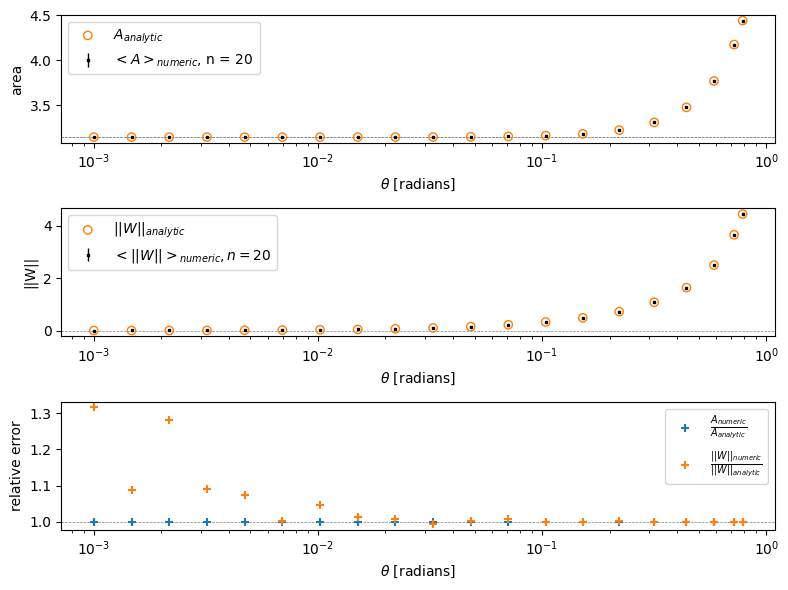

In [36]:
fig, axes = plt.subplots(3, 1, figsize = (8, 6))

axes[0].scatter(np.acos(thetai), results[:,0], label = "$A_{analytic}$", marker="o", color="None", edgecolor="C1")
axes[0].errorbar(np.acos(thetai), results[:,1], results[:,2] , label = f"$<A>_{{numeric}}$, n = {msim} ", marker = "s", markersize = 2, lw = 0, elinewidth=1, color ="k")

axes[0].set_ylabel("area")
axes[0].axhline(np.pi, lw = 0.5, ls="--", color ="grey", zorder = -1)

axes[1].scatter(np.acos(thetai), results[:,3], label = "$||W||_{analytic}$", marker="o", color="None", edgecolor="C1")
axes[1].errorbar(np.acos(thetai), results[:,4], results[:,5] , label = f"$<||W||>_{{numeric}}, n = {msim}$", marker = "s", markersize = 2, lw = 0, elinewidth=1, color ="k")

axes[1].set_ylabel("||W||")
axes[1].axhline(0, lw = 0.5, ls="--", color ="grey", zorder = -1)


axes[2].scatter(np.acos(thetai), results[:, 1] / results[:,0], label = "$\\frac{A_{numeric} }{ A_{analytic}}$", marker="+", color="C0")
axes[2].scatter(np.acos(thetai), results[:, 4] / results[:,3], label = "$\\frac{||W||_{numeric} }{ ||W||_{analytic}}$", marker="+", color="C1")
axes[2].axhline(1, ls="--", color ="grey", zorder = -1,  lw = 0.5)
axes[2].set_ylabel("relative error")
for ax in axes: 
    ax.legend()
    ax.set_xscale("log")
    ax.set_xlabel("$\\theta$ [radians]")


axes[0].axhline(np.pi, lw = 0.5, ls="--", color ="grey", zorder = -10)

plt.tight_layout()
plt.savefig("../temp/figures/validation_code_WA.png", dpi = 300)
plt.savefig("../temp/figures/validation_code_WA.pdf")
plt.show()


In [20]:
np.acos(thetai)*180 / np.pi

array([ 0.05729575,  0.08439933,  0.12432409,  0.18313482,  0.26976473,
        0.39737118,  0.58533027,  0.86216682,  1.26984475,  1.87000479,
        2.75289167,  4.04967624,  5.94801072,  8.70698508, 12.65593758,
       18.131857  , 25.26238235, 33.51735382, 41.2003979 , 45.        ])